In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import confidence_ellipse

In [31]:
data = pd.read_csv('./data/bayes_features.csv')
print(data.head())

     positive    negative  sentiment
0  -45.763393  -63.351354        1.0
1 -105.491568 -114.204862        1.0
2  -57.028078  -67.216467        1.0
3  -10.055885  -18.589057        1.0
4 -125.749270 -138.334845        1.0


Text(0, 0.5, 'Negative')

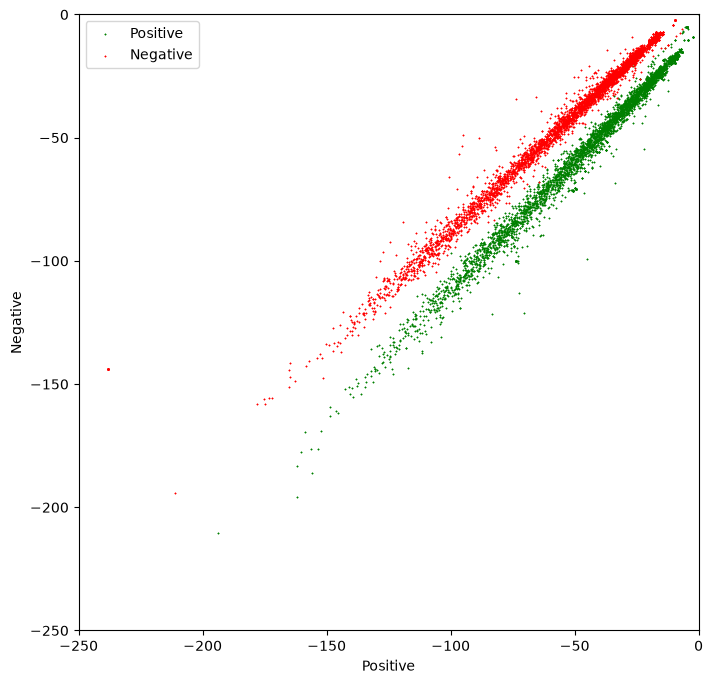

In [32]:
fig, ax = plt.subplots(figsize=(8, 8))
colors = ['red', 'green']
sentiments = ['Negative', 'Positive']
index = data.index

for sentiment in data.sentiment.unique():
    ix = index[data.sentiment == sentiment]
    ax.scatter(
        data.iloc[ix].positive, 
        data.iloc[ix].negative, 
        c=colors[int(sentiment)],
        s=0.1,
        marker='*',
        label=sentiments[int(sentiment)]
    ) 

ax.legend(loc='best')

plt.xlim(-250, 0)
plt.ylim(-250, 0)

plt.xlabel('Positive')
plt.ylabel('Negative')

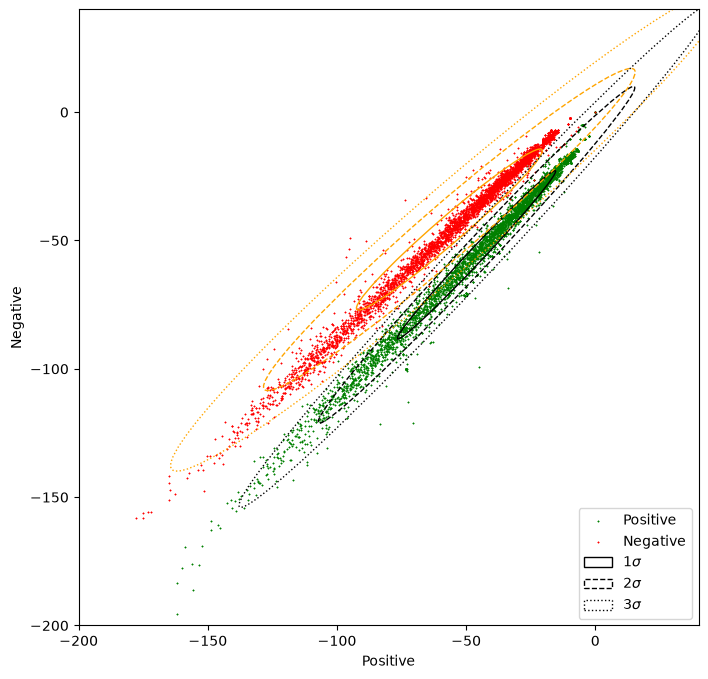

In [33]:
fig, ax = plt.subplots(figsize=(8, 8))
colors = ['red', 'green']
sentiments = ['Negative', 'Positive']
index = data.index

for sentiment in data.sentiment.unique():
    ix = index[data.sentiment == sentiment]
    ax.scatter(
        data.iloc[ix].positive,
        data.iloc[ix].negative,
        c=colors[int(sentiment)],
        s=0.1,
        marker='*',
        label=sentiments[int(sentiment)]
    )

plt.xlim(-200, 40)
plt.ylim(-200, 40)

plt.xlabel('Positive')
plt.ylabel('Negative')

data_pos = data[data.sentiment == 1]
data_neg = data[data.sentiment == 0]

confidence_ellipse(data_pos.positive, data_pos.negative, ax, n_std=1, edgecolor='black', label=r'$1\sigma$')
confidence_ellipse(data_neg.positive, data_neg.negative, ax, n_std=1, edgecolor='orange')

confidence_ellipse(data_pos.positive, data_pos.negative, ax, n_std=2, edgecolor='black', linestyle='--', label=r'$2\sigma$')
confidence_ellipse(data_neg.positive, data_neg.negative, ax, n_std=2, edgecolor='orange', linestyle='--')

confidence_ellipse(data_pos.positive, data_pos.negative, ax, n_std=3, edgecolor='black', linestyle=':', label=r'$3\sigma$')
confidence_ellipse(data_neg.positive, data_neg.negative, ax, n_std=3, edgecolor='orange', linestyle=':')

ax.legend(loc='lower right')

In [46]:
data2 = data.copy()

mask = data2.sentiment == 1

data2.loc[mask, 'negative'] = data2.loc[mask, 'negative'] * 1.5 + 50
data2.loc[mask, 'positive'] = data2.loc[mask, 'positive'] / 1.5 - 50

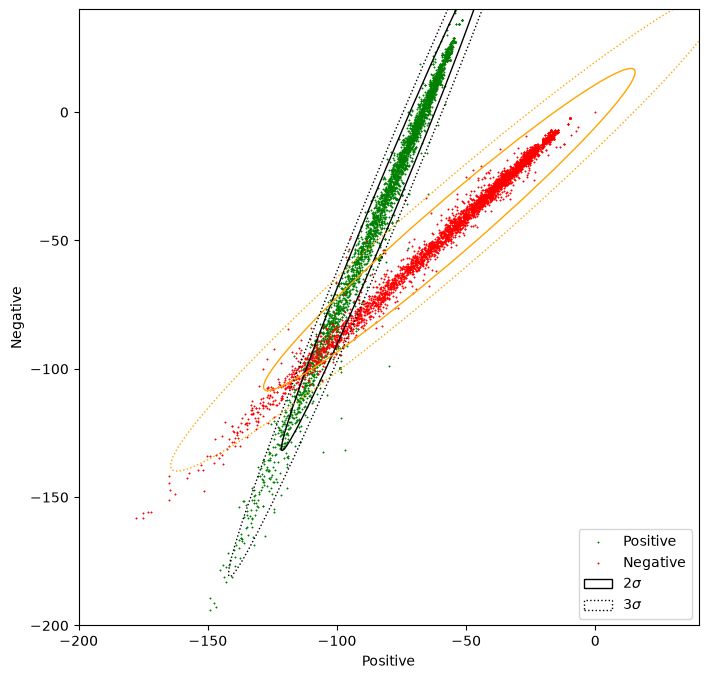

In [47]:
fig, ax = plt.subplots(figsize=(8, 8))
colors = ['red', 'green']
sentiments = ['Negative', 'Positive']
index = data2.index

for sentiment in data2.sentiment.unique():
    ix = index[data2.sentiment == sentiment]
    ax.scatter(
        data2.iloc[ix].positive,
        data2.iloc[ix].negative,
        c=colors[int(sentiment)],
        s=0.1,
        marker='*',
        label=sentiments[int(sentiment)]
    )

plt.xlim(-200, 40)
plt.ylim(-200, 40)

plt.xlabel('Positive')
plt.ylabel('Negative')

data_pos = data2[data2.sentiment == 1]
data_neg = data2[data2.sentiment == 0]

confidence_ellipse(data_pos.positive, data_pos.negative, ax, n_std=2, edgecolor='black', label=r'$2\sigma$')
confidence_ellipse(data_neg.positive, data_neg.negative, ax, n_std=2, edgecolor='orange')

confidence_ellipse(data_pos.positive, data_pos.negative, ax, n_std=3, edgecolor='black', linestyle=':', label=r'$3\sigma$')
confidence_ellipse(data_neg.positive, data_neg.negative, ax, n_std=3, edgecolor='orange', linestyle=':')

ax.legend(loc='lower right')